# Lab 7: Advanced Linear Regression & Feature Engineering

This lab will give you a chance to practice and experiment with:
* Using `statsmodels` and `scikit-learn` to go beyond simple linear regression
* Model selection using multiple predictors
* Feature engineering
* Model validation and cross-validation

Note: This lab only has 3 questions to give you more time to work on Project 3!

## Preliminaries

As a few quick reminders:
* You should be able to do questions 1-2 by Monday 
* Make sure your code exactly conforms to specifications (e.g. exactly matching variable names)
* Make sure your code works with any provided test code, and do NOT modify that test code unless explicitly stated
* When answering a specific question, ensure that all your data is within the relevant block.  For text-based answers, you will be asked to edit a specific markdown cell.  For code-based answers, please make sure all code is wholly contained within the relevant  `BEGIN` and `END` comments.
* Please be sure to run the first cell (to import libraries) any time you work on your code.  Please be sure to run all cells, from start to finish, before you submit.  Make sure they run without error, that all provided tests pass, etc.

In [55]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
from scipy import stats
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures


# Question 1: Regression on Penguins

In this question, we'll work with the Palmer Penguins data set, which provides measurements on 344 penguins.  We will try to use bill length, depth, and flipper length to predict bodymass.

In [56]:
pen_df = sns.load_dataset('penguins')
pen_df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


1a: Let's start by cleaning this dataset.  Drop all rows where any of the four quantitative variables we're interested in are NaN.

In [ ]:
# BEGIN QUESTION 1a
pen_df = pen_df.dropna(subset=["bill_length_mm", 
                               "bill_depth_mm", 
                               "flipper_length_mm", 
                               "body_mass_g"])
# END QUESTION 1a

try:
    if 340 <= pen_df.shape[0] <= 343:
        print("Public test for 1a passed")
    else:
        print("Public test for 1a FAILED")
except:
    print("Public test for 1a FAILED")
    
print(pen_df.shape[0], " rows remaining")

Public test for 1a passed
342  rows remaining


1b: Use `statsmodels` to fit a linear regression model where  bill length, bill depth, and flipper length are used to predict body mass.  Use the markdown cell to the equation of your LSRL?  As in Lab 6, be sure to type your work mathematically.  E.g. $\hat{y}=...$.  You can use $x_1, x_2,$ and $x_3$ in your equation (as long as you define what each is) or write out your quantitative variables directly (e.g. $\texttt{bill_length}$).  Clicking on this markdown cell will remind you of some of the math commands!

In [58]:
# BEGIN QUESTION 1b
X = pen_df[["bill_length_mm", "bill_depth_mm", "flipper_length_mm"]]
X = sm.add_constant(X)
y = pen_df["body_mass_g"]

model_sm = sm.OLS(y, X).fit()
model_sm.summary()


# END QUESTION 1b

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            body_mass_g   R-squared:                       0.761
Model:                            OLS   Adj. R-squared:                  0.759
Method:                 Least Squares   F-statistic:                     359.7
Date:                Fri, 27 Mar 2026   Prob (F-statistic):          8.19e-105
Time:                        14:30:05   Log-Likelihood:                -2526.7
No. Observations:                 342   AIC:                             5061.
Df Residuals:                     338   BIC:                             5077.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
=====================================================================================
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const             -6424.7647    561.469    -11.443      0.000   -7529.179   -5320.351
bill_length_mm        4.1618      5.329      0.781      0.435      -6.321      14.644
bill_depth_mm        20.0495     13.694      1.464      0.144      -6.887      46.986
flipper_length_mm    50.2692      2.477     20.293      0.000      45.397      55.142
==============================================================================
Omnibus:                        5.263   Durbin-Watson:                   2.016
Prob(Omnibus):                  0.072   Jarque-Bera (JB):                5.129
Skew:                           0.298   Prob(JB):                       0.0770
Kurtosis:                       3.065   Cond. No.                     5.46e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 5.46e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

$\widehat{\text{body mass}} = -6424.765 + 4.162(\text{bill length}) + 20.050(\text{bill depth}) + 50.269(\text{flipper length})$

where bill length and bill depth are measured in mm, flipper length is measured in mm, and predicted body mass is measured in grams.


1c: How do you interpret the coefficient of bill length?  How do you interpret that p-value for the F statistic?

The coefficient of bill length means that **holding bill depth and flipper length fixed**, a 1 mm increase in bill length is associated with an increase of about **4.16 grams** in predicted body mass.

The p-value for the F statistic is about \(8.19 \times 10^{-105}\), which is essentially 0. This means we have extremely strong evidence that the regression model is useful overall, so at least one of the predictors has a nonzero relationship with body mass.


1d: One penguin in the data set had a bill length of 44.1mm, a bill depth of 19.7mm, a flipper length of 196mm, and a body weight of 4400g.  What is the predicted weight for this penguin?  What is the residual?  Save your answers as `predwt` and `res`, respectively (you don't have to put them in a markdown cell). Use `statsmodels` to get the predicted weight, rather than computing it manually.

In [59]:
# BEGIN QUESTION 1d
new_peng = pd.DataFrame({
    "const": [1],
    "bill_length_mm": [44.1],
    "bill_depth_mm": [19.7],
    "flipper_length_mm": [196]
})

predwt = model_sm.predict(new_peng).iloc[0]
res = 4400 - predwt
# END QUESTION 1d


print("Predicted Weight: ", predwt)
print("Residual: ", res)

Predicted Weight:  4006.514828431151
Residual:  393.4851715688492


1e: Evaluate the overall fit of this model by (1) interpretting the $R^2$, (2) computing RSE (see our slides!), and (3) creating a normal QQ plot and residual plot.  Use the first code cell to find the RSE, use the next two code cells to create your plots, and use the final markdown cell to summarize your answer (interpretting the $R^2$ and RSE and analyzing your plots).  Hint: for (2), remember that `model_sm.ssr` gives the RSS!

In [60]:
# BEGIN QUESTION 1e
n = pen_df.shape[0]
p = 3
rse = np.sqrt(model_sm.ssr / (n - p - 1))
# END QUESTION 1e

print("RSE: ", rse)


try:
    if 350 <= rse <= 450:
        print("Public test for 1e passed")
    else:
        print("Public test for 1e FAILED")
except:
    print("Public test for 1e FAILED")
    

RSE:  393.40479657199114
Public test for 1e passed


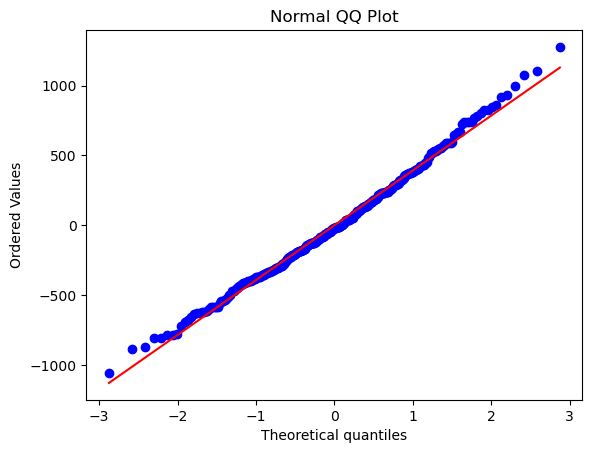

In [61]:
# Create your QQ plot here
stats.probplot(model_sm.resid, dist="norm", plot=plt)
plt.title("Normal QQ Plot")
plt.show()


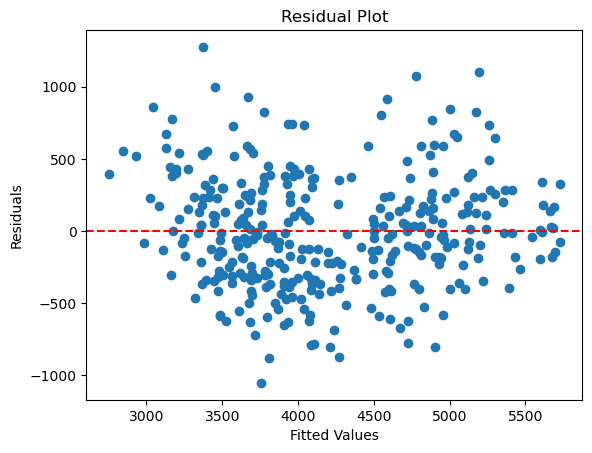

In [62]:
# Create your residual plot here
plt.scatter(model_sm.fittedvalues, model_sm.resid)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Fitted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()


The model has $R^2 \approx 0.7615$, so about **76.15\%** of the variability in penguin body mass is explained by bill length, bill depth, and flipper length.

The RSE is about **393.4 grams**, so the model's predictions are typically off by around 393 grams.

From the QQ plot, the residuals appear reasonably close to normal since the points stay fairly close to a straight line. From the residual plot, the residuals should look fairly randomly scattered around 0 without a strong curved pattern, which suggests that the linear model is a reasonable fit.


1f: By far the most statistically significant coefficient is flipper length.  Try fitting a simple linear regression model where you just use flipper length (and an intercept) to predict body weight. How do the RSE and $R^2$ compare with this reduced model to what you found above? (Be sure to give precise summary statistics!).  Do you think the full model with all three predictors or the reduced model with just flipper length is a better model?

In [63]:
# BEGIN QUESTION 1f
X_red = pen_df[["flipper_length_mm"]]
X_red = sm.add_constant(X_red)
model_red = sm.OLS(y, X_red).fit()
model_red.summary()
# END QUESTION 1f


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            body_mass_g   R-squared:                       0.759
Model:                            OLS   Adj. R-squared:                  0.758
Method:                 Least Squares   F-statistic:                     1071.
Date:                Fri, 27 Mar 2026   Prob (F-statistic):          4.37e-107
Time:                        14:30:06   Log-Likelihood:                -2528.4
No. Observations:                 342   AIC:                             5061.
Df Residuals:                     340   BIC:                             5069.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
=====================================================================================
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const             -5780.8314    305.815    -18.903      0.000   -6382.358   -5179.305
flipper_length_mm    49.6856      1.518     32.722      0.000      46.699      52.672
==============================================================================
Omnibus:                        5.634   Durbin-Watson:                   2.176
Prob(Omnibus):                  0.060   Jarque-Bera (JB):                5.585
Skew:                           0.313   Prob(JB):                       0.0613
Kurtosis:                       3.019   Cond. No.                     2.89e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.89e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [64]:
# BEGIN QUESTION 1f
# Use this cell to get the RSE
rse = np.sqrt(model_red.ssr / (pen_df.shape[0] - 2))
# END QUESTION 1f
print(rse)

394.27817750906166


For the reduced model using only flipper length, the summary statistics are:

- $R^2 \approx 0.7590$
- $RSE \approx 394.28$

For the full model with all three predictors, the summary statistics are:

- $R^2 \approx 0.7615$
- $RSE \approx 393.40$

These are extremely close. The full model fits slightly better because it has a slightly larger \(R^2\) and slightly smaller RSE, but the reduced model is almost just as good while being much simpler. Because of that, I think the reduced model is very competitive, though the full model is technically a bit better in terms of fit.


1g: Dane Brammaj observes that the $p$-value for bill length was reasonably high in our first model and says "we don't have meaningful evidence that bill length predicts body mass!"  Fit a simple linear regression model where you just use bill length (and an intercept) to predict body weight.  The $p$-value should now be statistically significant.  Explain to Dane what is going on here. 

In [65]:
# BEGIN QUESTION 1g
X_bill = pen_df[["bill_length_mm"]]
X_bill = sm.add_constant(X_bill)
model_bill = sm.OLS(y, X_bill).fit()
model_bill.summary()
# END QUESTION 1g


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            body_mass_g   R-squared:                       0.354
Model:                            OLS   Adj. R-squared:                  0.352
Method:                 Least Squares   F-statistic:                     186.4
Date:                Fri, 27 Mar 2026   Prob (F-statistic):           3.81e-34
Time:                        14:30:06   Log-Likelihood:                -2697.0
No. Observations:                 342   AIC:                             5398.
Df Residuals:                     340   BIC:                             5406.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==================================================================================
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const            362.3067    283.345      1.279      0.202    -195.024     919.637
bill_length_mm    87.4153      6.402     13.654      0.000      74.823     100.008
==============================================================================
Omnibus:                        5.671   Durbin-Watson:                   0.863
Prob(Omnibus):                  0.059   Jarque-Bera (JB):                4.857
Skew:                          -0.211   Prob(JB):                       0.0882
Kurtosis:                       2.597   Cond. No.                         359.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Dane is mixing up two different ideas. In the multiple regression model, the p-value for bill length tests whether bill length adds useful information **after controlling for bill depth and flipper length**. Since those predictors are related to bill length, much of the information in bill length overlaps with information already in the model.

But in a simple linear regression using only bill length, bill length is the only predictor, so it captures that relationship with body mass by itself and becomes statistically significant.

So bill length can be significant alone, but not significant once other correlated predictors are already included. This is a consequence of correlation among predictors, sometimes called multicollinearity.


# Question 2: Feature Selection

The following data set gives information about baseball players.  It gives several statistics from their 1986 season, including
- AtBat: Number of times at bat in 1986.
- Hits: Number of hits in 1986.
- HmRun: Number of home runs in 1986.
- Runs: Number of runs scored in 1986.
- RBI: Number of runs batted in in 1986.
- Walks: Number of walks in 1986.
- PutOuts: Number of putouts in 1986 (typically catching a fly ball or tagging a base).
- Assists: Number of assists in 1986 (throwing the ball to a teammate who makes a putout).
- Errors: Number of errors in 1986.
- Years: Number of years played in the major leagues.

As well as the 1987 annual salary (in thousands of dollars).  Our goal will to be to fit a linear regression model to use 1986 performance data to predict 1987 salary.

In this question, we'll run forward selection to find the best model with 3 predictors.  Let's start by loading the data!

In [66]:
url = "https://raw.githubusercontent.com/JWarmenhoven/ISLR-python/master/Notebooks/Data/Hitters.csv"
hitters_df = pd.read_csv(url, index_col=0).dropna()
# An artifact of the original data is that player names have dashes in front of them
# This cleans those for readability
hitters_df.index = hitters_df.index.str.lstrip('-')
# Drop categorical columns
hitters_df = hitters_df[['AtBat', 'Hits', 'HmRun', 'Runs', 'RBI', 'Walks', 'Years', 
                        'PutOuts', 'Assists','Errors', 'Salary']]
hitters_df.head()

,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,PutOuts,Assists,Errors,Salary
Alan Ashby,315,81,7,24,38,39,14,632,43,10,475.0
Alvin Davis,479,130,18,66,72,76,3,880,82,14,480.0
Andre Dawson,496,141,20,65,78,37,11,200,11,3,500.0
Andres Galarraga,321,87,10,39,42,30,2,805,40,4,91.5
Alfredo Griffin,594,169,4,74,51,35,11,282,421,25,750.0


2a: Let's start forward selection: find the best model with a single predictor.    You will have to fit 10 linear models in `statsmodels`, each using an intercept and just one predictor.  Then, pick the one with the biggest $R^2.$  You can do this manually and tediously, or with a loop.  I strongly suggest a loop :).

In terms of showing your work, use the following code cell to try each model.  Then use the subsequent markdown cell to record the $R^2$ of each of the models you fit and clearly identify the best.  Finally, use the final code cell to run and show summary output from the best model you found.  Call that model `model1` (instead of, e.g., `model_sm`).

In [67]:
#2a: Use this code cell for your scratch work
r2_dict = {}

for col in ['AtBat', 'Hits', 'HmRun', 'Runs', 'RBI', 'Walks', 'Years',
            'PutOuts', 'Assists', 'Errors']:
    X = hitters_df[[col]]
    X = sm.add_constant(X)
    y = hitters_df["Salary"]
    model = sm.OLS(y, X).fit()
    r2_dict[col] = model.rsquared

r2_dict


{'AtBat': np.float64(0.15584409882649575),
 'Hits': np.float64(0.1924355256447965),
 'HmRun': np.float64(0.11766826240248207),
 'Runs': np.float64(0.17628120981913598),
 'RBI': np.float64(0.20201167389953556),
 'Walks': np.float64(0.19701814464459022),
 'Years': np.float64(0.16052602714776776),
 'PutOuts': np.float64(0.09028844404501535),
 'Assists': np.float64(0.0006469969966702571),
 'Errors': np.float64(2.916757670234915e-05)}

*2a: Fill in this markdown cell with the $R^2$ you get from each model.  The first is filled in for you as a sanity check / to show the formatting*

- Just  AtBat :  0.15584409882649541
- Just  Hits :  0.1924355256447965
- Just  HmRun :  0.11766826240248207
- Just  Runs :  0.17628120981913598
- Just  RBI :  0.20201167389953556
- Just  Walks :  0.19701814464459022
- Just  Years :  0.16052602714776776
- Just  PutOuts :  0.09028844404501535
- Just  Assists :  0.0006469969966702571
- Just  Errors : 2.916757670234915e-05

Best predictor: RBI


In [68]:
# 2a: Use this code cell to show your best model with a single predictor
# This code cell should fit a model with a single predictor (and intercept)
# and then show the summary

X = hitters_df[["RBI"]]
X = sm.add_constant(X)
y = hitters_df["Salary"]
model1 = sm.OLS(y, X).fit()


try:
    if 0.2 <= model1.rsquared <= 0.21:
        print("Public test for 2a passed")
    else:
        print("Public test for 2a FAILED")
except:
    print("Public test for 2a FAILED")
    

model1.summary()

Public test for 2a passed


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Salary   R-squared:                       0.202
Model:                            OLS   Adj. R-squared:                  0.199
Method:                 Least Squares   F-statistic:                     66.07
Date:                Fri, 27 Mar 2026   Prob (F-statistic):           1.76e-14
Time:                        14:30:06   Log-Likelihood:                -1950.4
No. Observations:                 263   AIC:                             3905.
Df Residuals:                     261   BIC:                             3912.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        132.5925     55.515      2.388      0.018      23.277     241.908
RBI            7.8337      0.964      8.128      0.000       5.936       9.731
==============================================================================
Omnibus:                       80.623   Durbin-Watson:                   1.940
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              229.908
Skew:                           1.359   Prob(JB):                     1.19e-50
Kurtosis:                       6.687   Cond. No.                         128.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

2b: Moving onward!  Above, you found the best model with a single predictor (and intercept). Now lets add a new predictor.

As above, find the best model that has (1) an intercept, (2) the predictor you found in 2a, and (3) one more predictor.  This will involve trying 9 more linear models and finally picking the one with the biggest $R^2$.  Again, I suggest a loop.

Emulate the process above. Use the following code cell to try each model.  Then use the subsequent markdown cell to record the $R^2$ of each of the models you fit and clearly identify the best.  Finally, use the final code cell to run and show summary output from the best model you found.  Call that model `model2` 

In [69]:
#2b: Use this code cell for your scratch work
r2_dict2 = {}

for col in ['AtBat', 'Hits', 'HmRun', 'Runs', 'Walks', 'Years',
            'PutOuts', 'Assists', 'Errors']:
    X = hitters_df[["RBI", col]]
    X = sm.add_constant(X)
    y = hitters_df["Salary"]
    model = sm.OLS(y, X).fit()
    r2_dict2[col] = model.rsquared

r2_dict2


{'AtBat': np.float64(0.20574767046860198),
 'Hits': np.float64(0.22079138242049845),
 'HmRun': np.float64(0.20735428217282348),
 'Runs': np.float64(0.2144133755304961),
 'Walks': np.float64(0.2542656532511707),
 'Years': np.float64(0.3212382064748466),
 'PutOuts': np.float64(0.2304519951877746),
 'Assists': np.float64(0.20201974587415505),
 'Errors': np.float64(0.20744699706571113)}

*2b: Fill in this markdown cell with the $R^2$ you get from each model.  The first is filled in for you as a sanity check / to show the formatting.  Ultimately you will report the results of 9 models*

- Just RBI and AtBat :  0.20574767046860198
- Just RBI and Hits : 0.22079138242049878
- Just RBI and HmRun : 0.20735428217282326
- Just RBI and Runs : 0.2144133755304961
- Just RBI and Walks : 0.2542656532511708
- Just RBI and Years : 0.3212382064748467
- Just RBI and PutOuts : 0.2304519951877747
- Just RBI and Assists : 0.20201974587415494
- Just RBI and Errors : 0.20744699706571101

Best 2 predictors using forward selection: RBI and Years

In [70]:
# 2b: Use this code cell to show your best model with two predictors using forward selection
# This code cell should fit a model with two predictors (and intercept)
# and then show the summary
X = hitters_df[["RBI", "Years"]]
X = sm.add_constant(X)
y = hitters_df["Salary"]
model2 = sm.OLS(y, X).fit()



try:
    if 0.3 <= model2.rsquared <= 0.35:
        print("Public test for 2b passed")
    else:
        print("Public test for 2b FAILED")
except:
    print("Public test for 2b FAILED")
    

model2.summary()

Public test for 2b passed


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Salary   R-squared:                       0.321
Model:                            OLS   Adj. R-squared:                  0.316
Method:                 Least Squares   F-statistic:                     61.53
Date:                Fri, 27 Mar 2026   Prob (F-statistic):           1.33e-22
Time:                        14:30:07   Log-Likelihood:                -1929.1
No. Observations:                 263   AIC:                             3864.
Df Residuals:                     260   BIC:                             3875.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -66.5050     59.157     -1.124      0.262    -182.993      49.983
RBI            7.0467      0.898      7.846      0.000       5.278       8.815
Years         32.7715      4.849      6.758      0.000      23.223      42.320
==============================================================================
Omnibus:                      113.898   Durbin-Watson:                   1.938
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              503.392
Skew:                           1.765   Prob(JB):                    4.90e-110
Kurtosis:                       8.786   Cond. No.                         149.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

2c: And it's our final step of forward selection to get three predictors!  Above, you found the best model with attainable by adding a single predictor to `model1`. Now lets add one more predictor.

As above, find the best model that has (1) an intercept, (2) the predictors from `model2`, and (3) one more predictor.  This will involve trying 8 more linear models and finally picking the one with the biggest $R^2$.  Again, I suggest a loop.

Emulate the process above. Use the following code cell to try each model.  Then use the subsequent markdown cell to record the $R^2$ of each of the models you fit and clearly identify the best.  Finally, use the final code cell to run and show summary output from the best model you found.  Call that model `model3` 

In [71]:
#2c: Use this code cell for your scratch work
r2_dict3 = {}

for col in ['AtBat', 'Hits', 'HmRun', 'Runs', 'Walks',
            'PutOuts', 'Assists', 'Errors']:
    X = hitters_df[["RBI", "Years", col]]
    X = sm.add_constant(X)
    y = hitters_df["Salary"]
    model = sm.OLS(y, X).fit()
    r2_dict3[col] = model.rsquared

r2_dict3


{'AtBat': np.float64(0.3343471636247719),
 'Hits': np.float64(0.3558915593959636),
 'HmRun': np.float64(0.32691239739336286),
 'Runs': np.float64(0.35256491318842786),
 'Walks': np.float64(0.36258575690721806),
 'PutOuts': np.float64(0.3577982014484208),
 'Assists': np.float64(0.32212846285182783),
 'Errors': np.float64(0.32138060578050176)}

- RBI, Years, and AtBat : 0.334347163624772
- RBI, Years, and Hits : 0.35589155939596384
- RBI, Years, and HmRun : 0.326912397393363
- RBI, Years, and Runs : 0.35256491318842786
- RBI, Years, and Walks : 0.3625857569072183
- RBI, Years, and PutOuts : 0.35779820144842067
- RBI, Years, and Assists : 0.32212846285182795
- RBI, Years, and Errors : 0.32138060578050187

Best 3 predictors using forward selection: RBI, Years, and Walks


In [72]:
# 2c: Use this code cell to show your best model with two predictors using forward selection
# This code cell should fit a model with two predictors (and intercept)
# and then show the summary

X = hitters_df[["RBI", "Years", "Walks"]]
X = sm.add_constant(X)
y = hitters_df["Salary"]
model3 = sm.OLS(y, X).fit()



try:
    if 0.35 <= model3.rsquared <= 0.4:
        print("Public test for 2c passed")
    else:
        print("Public test for 2c FAILED")
except:
    print("Public test for 2c FAILED")
    
model3.summary()
hitters_df["intercept"] = 1


Public test for 2c passed


2d: Dane Brammaj exclaims "Above, I found the very best linear regression model with three predictors."  His nemesis, Ket Moore Dayton (read: get more data) is a bit more thoughtful and shows Dane the following model, which has a better (bigger) $R^2$.  In the markdown cell below, briefly explain how it is possible that forward selection did not find the best model with 3 predictors.

In [73]:
X = hitters_df[['intercept', "Hits", "Years", "PutOuts"]]
y = hitters_df["Salary"]
model_ket = sm.OLS(y, X).fit()
model_ket.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Salary   R-squared:                       0.382
Model:                            OLS   Adj. R-squared:                  0.375
Method:                 Least Squares   F-statistic:                     53.32
Date:                Fri, 27 Mar 2026   Prob (F-statistic):           7.16e-27
Time:                        14:30:07   Log-Likelihood:                -1916.8
No. Observations:                 263   AIC:                             3842.
Df Residuals:                     259   BIC:                             3856.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
intercept   -231.2499     66.275     -3.489      0.001    -361.757    -100.743
Hits           3.7217      0.512      7.267      0.000       2.713       4.730
Years         37.4245      4.600      8.135      0.000      28.366      46.483
PutOuts        0.3173      0.083      3.843      0.000       0.155       0.480
==============================================================================
Omnibus:                      129.389   Durbin-Watson:                   2.047
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              805.931
Skew:                           1.898   Prob(JB):                    9.87e-176
Kurtosis:                      10.690   Cond. No.                     1.24e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.24e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

Forward selection does **not** guarantee the best overall model with 3 predictors because it is a greedy procedure. At each step, it chooses the predictor that gives the biggest immediate improvement in \(R^2\), but that choice may prevent it from reaching the best possible 3-variable combination later.

So even though forward selection chose `RBI`, `Years`, and `Walks`, another combination such as `Hits`, `Years`, and `PutOuts` can still end up with a larger \(R^2\).


Well, that was kinda fun and kinda tedious.  It would be a pain to do that with many more predictors and to get a larger model.  Luckily sci-learn has a tool for forward selection called `SequentialFeatureSelector`.  Lets see it in action below, where we have it print out (1) the best 3 predictors it finds and (2) the MSE

In [74]:
X = hitters_df.drop(columns="Salary")
y = hitters_df['Salary']
all_indices = np.arange(len(X))


# By default, SequentialFeatureSelector uses cross validation
# We have to tell it to use all the data as training data AND as test data
# to emulate the forward selection approach we just did
no_cv_split = [(all_indices, all_indices)]
# ---------------------------

# Set up forward selection
model = LinearRegression()

sfs = SequentialFeatureSelector(
    estimator=model,              # tell it we're using linear regression (our model)
    n_features_to_select=3,       # select 3 features to select
    direction='forward',          # do forward selection
    cv=no_cv_split,               # use all the data
    scoring='r2'                  # at each step, maximize R^2
)

# Fit the selector and extract the names
sfs.fit(X, y)
selected_features = X.columns[sfs.get_support()]
print("--- Forward Selection Results ---")
print("Best 3 predictors: ", list(selected_features))

# Get the MSE of that model
X_subset = X[selected_features]
model.fit(X_subset, y)
y_pred = model.predict(X_subset)
mse = mean_squared_error(y, y_pred)
print("MSE: ", mse)

--- Forward Selection Results ---
Best 3 predictors:  ['RBI', 'Walks', 'Years']
MSE:  129225.71072453629


2e: Adapt the above code to run forward selection to get a model 5 predictors.  What are those 5 predictors?

In [75]:
# BEGIN QUESTION 2e
X = hitters_df.drop(columns="Salary")
y = hitters_df["Salary"]
all_indices = np.arange(len(X))
no_cv_split = [(all_indices, all_indices)]

model = LinearRegression()
sfs = SequentialFeatureSelector(
    estimator=model,
    n_features_to_select=5,
    direction='forward',
    cv=no_cv_split,
    scoring='r2'
)

sfs.fit(X, y)
selected_features = X.columns[sfs.get_support()]
print(list(selected_features))
# END QUESTION 2e


['Hits', 'RBI', 'Walks', 'Years', 'PutOuts']


# Question 3: Feature Engineering

In this question, we'll work with a tips dataset.  Here `day` takes on four values (thursday, friday, saturday, and sunday).  Our goal is to predict the tip

In [76]:
tips = sns.load_dataset("tips")
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


3a: Create a dataset where `X` includes just `total_bill`, `day`, and an intercept (in a column named `intercept`), and where `y` includes just `tip` (both should be dataframes).  Then split X and y into training and test sets called `X_train, X_test, y_train,` and `y_test`.  You should use `random_state=42` for reproducibility, and your train set should have 80% of the data.

In [77]:
# BEGIN QUESTION 3a
X = tips[["total_bill", "day"]].copy()
X["intercept"] = 1
X = X[["intercept", "total_bill", "day"]]

y = tips[["tip"]].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.8, random_state=42
)
# END QUESTION 3a


try:
    if (X_train["intercept"][12]==1 and X_train.iloc[0, 1]==13.28 
                                    and X_train.size==585 
                                    and y_train.size==195 
                                    and y_test.size==49):
        print("Public test for 3a passed")
    else:
        print("Public test for 3a FAILED")
except:
    print("Public test for 3a FAILED")

Public test for 3a passed


3b: Transform `day` from a single categorical column into several quantitative columns using `get_dummies` in both `X_train` and `X_test`

**Note:** If you rerun the following cell multiple times, you may run into issues.  If you do, rerun the cell where you first created `X_train` and `X_test`.  Then come back to this cell

In [ ]:
# BEGIN QUESTION 3b
X_train = pd.get_dummies(X_train, columns=["day"],
                          drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, columns=["day"],
                         drop_first=True, dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
# END QUESTION 3b


try:
    if (X_train.size==975 and X_test.size==245 
        and X_train.loc[228, "day_Sat"]==1):
        print("Public test for 3b passed")
    else:
        print("Public test for 3b FAILED")
except:
    print("Public test for 3b FAILED")
    
X_train.head()

Public test for 3b passed


,intercept,total_bill,day_Fri,day_Sat,day_Sun
228,1,13.28,0,1,0
208,1,24.27,0,1,0
96,1,27.28,1,0,0
167,1,31.71,0,0,1
84,1,15.98,0,0,0


3c: Add a new feature  `total_bill_squared` storing the `total_bill` squared to both `X_train` and `X_test`.  Do this directly working with `X_train` and `X_test` as DataFrames (i.e. NOT using PolynmoialFeatures).  

In [ ]:
# BEGIN QUESTION 3c
X_train["total_bill_squared"] = X_train["total_bill"] ** 2
X_test["total_bill_squared"] = X_test["total_bill"] ** 2
# END QUESTION 3c

try:
    if (X_train.size==1170 and X_test.size==294 and
         392<=X_test.loc[24, "total_bill_squared"]<=394):
        print("Public test for 3c passed")
    else:
        print("Public test for 3c FAILED")
except:
    print("Public test for 3c FAILED")
    

Public test for 3c passed


3d: Use statsmodels to fit a regression model using `total_bill`, `total_bill_squared`, and your `day` variables (and an intercept) to predict `tip` using your train set.  How do you interpret the coefficient of `day_Sun`?  What is the MSE on the train set?  What is the MSE on the test set?

In [80]:
# BEGIN QUESTION 3d
model_tips = sm.OLS(y_train, X_train).fit()

yhat_train = model_tips.predict(X_train)
yhat_test = model_tips.predict(X_test)

mse_train = mean_squared_error(y_train, yhat_train)
mse_test = mean_squared_error(y_test, yhat_test)

print(model_tips.summary())
print("Train MSE:", mse_train)
print("Test MSE:", mse_test)
# END QUESTION 3d

                            OLS Regression Results                            
Dep. Variable:                    tip   R-squared:                       0.438
Model:                            OLS   Adj. R-squared:                  0.423
Method:                 Least Squares   F-statistic:                     29.41
Date:                Fri, 27 Mar 2026   Prob (F-statistic):           5.03e-22
Time:                        14:30:08   Log-Likelihood:                -289.70
No. Observations:                 195   AIC:                             591.4
Df Residuals:                     189   BIC:                             611.0
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
intercept              1.2123      0

Because `day_Thur` is the baseline category, the coefficient of `day_Sun` means that holding `total_bill` and `total_bill_squared` fixed, a meal on Sunday is predicted to have a tip about 0.0979 dollars higher than a similar meal on Thursday.

The training MSE is about **1.1427**.

The test MSE is about **0.6285**.


3e: Consider fitting a model where you only use an intercept and powers of `total_bill`.  Make an MSE vs degree curve, as in lecture, showing the MSE on the train and test set as you increase the max degree of your model from 1 to 8.  Briefly describe what information you get from the MSE curve in the subsequent markdown cell. 

For instance, here is how you'd get the MSE on training data for a model with the intercept, `total_bill`, and (`total_bill`$)^2$.  Note that this MSE, 1.15, should be higher than what you found in 3d for the train set (even if just slightly), because the model in 3d had the same predictors + day of week.

Your code should output a single scatterplot, showing the MSE curves for both the test and train set in separate colors.  Hint: you can adapt a lot of the code from the week 9 code demos!

In [81]:
# Example code: run, but do not edit, this cell

# Reset our X to only include `total_bill`
X_train = X_train[["total_bill"]]
X_test = X_test[["total_bill"]]

# Fit a simple linear model on train set (degree 2)
poly = PolynomialFeatures(degree=2, include_bias=False)
poly.set_output(transform="pandas")


X_train_deg2 = poly.fit_transform(X_train)
model = LinearRegression()
model.fit(X_train_deg2,  y_train);

# Get y-hats for training data to compute MSE on training data
y_pred = model.predict(X_train_deg2)

# Compute MSE on training data
mse = mean_squared_error(y_train, y_pred)
print("MSE: ", mse)

MSE:  1.154541288928948


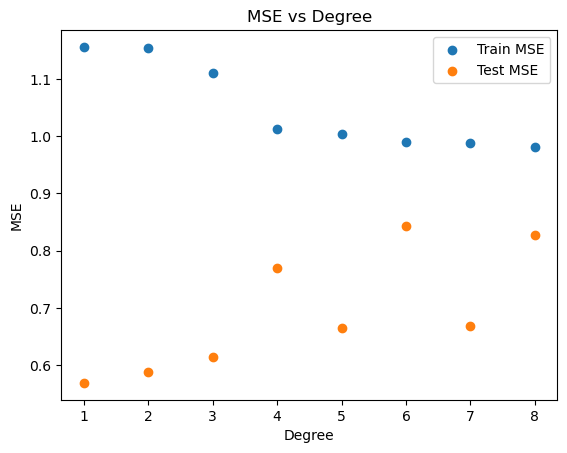

Public test for 3e passed
mselist_train[3]:  1.013480077264204
mselist_test[3]:  0.7697714920517067


In [82]:
degs = [i for i in range(1, 9)]
mselist_train = []
mselist_test = []

# BEGIN QUESTION 3e
for deg in degs:
    poly = PolynomialFeatures(degree=deg, include_bias=False)
    poly.set_output(transform="pandas")
    
    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)
    
    model = LinearRegression()
    model.fit(X_train_poly, y_train)
    
    yhat_train = model.predict(X_train_poly)
    yhat_test = model.predict(X_test_poly)
    
    mselist_train.append(mean_squared_error(y_train, yhat_train))
    mselist_test.append(mean_squared_error(y_test, yhat_test))

plt.scatter(degs, mselist_train, label="Train MSE")
plt.scatter(degs, mselist_test, label="Test MSE")
plt.xlabel("Degree")
plt.ylabel("MSE")
plt.title("MSE vs Degree")
plt.legend()
plt.show()
# END QUESTION 3e

# Do not edit the following code:
try:
    if (len(mselist_test)==len(mselist_train)==8) and 1.14 <= mselist_train[1] <= 1.16:
        print("Public test for 3e passed")
    else:
        print("Public test for 3e FAILED")
except:
    print("Public test for 3e FAILED")
    
print("mselist_train[3]: ", mselist_train[3])
print("mselist_test[3]: ", mselist_test[3])


The training MSE decreases as the polynomial degree increases, which is expected because more flexible models can fit the training data more closely.

The test MSE is lowest at degree 1 and then generally increases as the degree gets larger. This suggests that higher-degree models are starting to overfit the training data and do not generalize as well to new data.

So based on the MSE curve, a simple low-degree model, especially degree 1, appears to be the best choice here.


## Lab Check Hint for Lab 7

For this upcoming lab check, you should feel good about:
* Reading and interpretting the output from statsmodels for regression with multiple predictors: getting the equation of the LSRL, interpretting slopes, identifying/interpretting p-values for individual features and the F statistic (as in 1)
* Being able to use model output for forward selection and understand why forward selection does not necessarily produce the best model with a given number of predictors) (as in 2a-d)
* Understand what a train/test curve typically looks like (for each of the train and test set lines) and how to interpret this in the context of overfitting (as in 3)



# Submission Instructions: due 3/27 at 5pm

We will submit this lab as a PDF.
1. Hit "Kernel --> Restart & Run All"
2. Make sure that all of your cells run and that any output necessary for grading is shown.  Be sure that you pass the provided tests.
3. Create a PDF of your notebook.  To do so, (1) hit File -> Download as -> HTML (or potentially Save and File -> Export Notebook As -> HTML, depending on your version of Jupyter/OS) (2) open that HTML file in Google Chrome (I drag from downloads into a new Chrome tab), and (3) save that HTML file as a PDF (I type `ctrl+P` to print and then select `Save as PDF` as my destination).  Note that this is a bit more involved than just saving as a PDF directly from Jupyter, but usually leads to better-formatted notebooks so **please follow this process exactly.**
4. Skim the PDF and make sure all your code and written responses are fully visible.  If you notice anything (like your code lines are too long and get cut off; your written answers are cut off), fix those issues and repeat the above process. If I cannot see your work, it will not be graded.  It is OK if certain tables are too wide (that's unavoidable) and it's fine if my code/instructions isn't fully visible, but I need to be able to read all of your code/comments/charts.
5. Upload that PDF to Gradescope.  If you run into any issues, please reach out to me before the deadline and document that you've completed everything (e.g. by emailing me a copy of your Jupyter notebook).